Cell 1 — READ-ONLY inspection + duplicate check


In [1]:
import os, re, glob, csv, xml.etree.ElementTree as ET
from collections import Counter

ZT = "/content/drive/MyDrive/lifeguard_test"

def video_id_of(s):
    m = re.match(r"^(.*?)_\d{2}-\d{2}-\d{2}--\d{2}-\d{2}-\d{2}_", s)
    return m.group(1) if m else None

xmls = sorted(glob.glob(f"{ZT}/annotations/*.xml"))
canonical = [p for p in xmls if re.search(r"_\d{2}-\d{2}-\d{2}--", os.path.basename(p))]
short = [p for p in xmls if p not in canonical]

r0 = ET.parse(canonical[0]).getroot()
print("labels:", [l.find("name").text for l in r0.iter("label")])
print("original_size:", r0.find(".//original_size").find("width").text, "x", r0.find(".//original_size").find("height").text)

box_cls, frames, files_with = Counter(), 0, Counter()
for p in canonical:
    r = ET.parse(p).getroot(); has = set()
    for im in r.iter("image"):
        frames += 1
        for b in im.iter("box"):
            box_cls[b.get("label")] += 1; has.add(b.get("label"))
    for c in has: files_with[c] += 1
print("canonical XMLs:", len(canonical), "| short-named:", [os.path.basename(s) for s in short])
print("frames:", frames, "| boxes:", dict(box_cls), "| files with class:", dict(files_with))

def norm(p): return ET.tostring(ET.parse(p).getroot(), encoding="unicode")
for s in short:
    base = os.path.splitext(os.path.basename(s))[0]
    for c in canonical:
        if os.path.basename(c).startswith(base + "_"):
            print(f"{base}  vs  {os.path.basename(c)}  identical={norm(s) == norm(c)}")

labels: ['swim', 'drown']
original_size: 224 x 224
canonical XMLs: 91 | short-named: ['XPPOcJNk1S8.xml', 'Z9npOp9WhWM.xml']
frames: 48070 | boxes: {'drown': 24506, 'swim': 75096} | files with class: {'swim': 69, 'drown': 55}
XPPOcJNk1S8  vs  XPPOcJNk1S8_00-00-05--00-00-20_0-70--0-27--0-11.xml  identical=True
Z9npOp9WhWM  vs  Z9npOp9WhWM_00-00-00--00-00-13_0-56--0-32--0-66.xml  identical=False
Z9npOp9WhWM  vs  Z9npOp9WhWM_00-00-04--00-00-15_0-46--0-32--0-66.xml  identical=False
Z9npOp9WhWM  vs  Z9npOp9WhWM_00-00-22--00-00-34_0-04--0-25--0-17.xml  identical=True


Cell 2 — Video-level 70/20/10 split (stratified, seed 42)


In [3]:
import random
random.seed(42)

video_has_drown = {}
for p in canonical:
    vid = video_id_of(os.path.splitext(os.path.basename(p))[0])
    r = ET.parse(p).getroot()
    has_d = any(b.get("label") == "drown" for im in r.iter("image") for b in im.iter("box"))
    video_has_drown.setdefault(vid, False)
    video_has_drown[vid] = video_has_drown[vid] or has_d

drown_v = sorted(v for v, d in video_has_drown.items() if d)
swim_v  = sorted(v for v, d in video_has_drown.items() if not d)

def split3(group):
    g = group[:]; random.shuffle(g)
    nt, nv = round(len(g)*0.10), round(len(g)*0.20)
    return set(g[nt+nv:]), set(g[nt:nt+nv]), set(g[:nt])   # train, val, test

train, val, test = set(), set(), set()   # FIXED: three separate sets
for grp in (drown_v, swim_v):
    tr, va, te = split3(grp); train |= tr; val |= va; test |= te

assert not (train & val) and not (train & test) and not (val & test)
print("train:", len(train), "| val:", len(val), "| test:", len(test), "| total:", len(train)+len(val)+len(test))
print("test videos:", sorted(test))

train: 43 | val: 12 | test: 7 | total: 62
test videos: ['I-EKqLdbysk', 'L0KTqPloUiU', 'OAzlohkIVp0', 'T5mDQeDkca0', 'Y_nXru9bjbA', 'iVMA7GhSJjM', 'wQdAEA4a8IA']


Cell 3 — Extract frames + convert CVAT → YOLO (writes a NEW dir)


In [4]:
import os, re, glob, csv, subprocess
import xml.etree.ElementTree as ET

ZT = "/content/drive/MyDrive/lifeguard_test"
OUT = "/content/drive/MyDrive/lifeguard_datasets/Z5cc_v1"   # change if you prefer local

if os.path.isdir(OUT) and os.listdir(OUT):
    raise SystemExit(f"STOP: {OUT} exists and is not empty — choose a new versioned path.")

CLASSES = {"swim": 0, "drown": 1}

def snippet_name(video_id, start, end, x, y, width):
    start = str(start)[:-3].replace(':', '-'); end = str(end)[:-3].replace(':', '-')
    x = str(x)[:-2].replace('.', '-'); y = str(y)[:-2].replace('.', '-'); width = str(width)[:-2].replace('.', '-')
    return f"{video_id}_{start}--{end}_{x}--{y}--{width}"

clips = []
with open(f"{ZT}/datalist.csv", newline="") as f:
    for row in csv.reader(f):
        if len(row) < 7: continue
        video_id, start, end, x, y, width, flag = row[:7]
        if flag.strip() != "y": continue
        snip = snippet_name(video_id, start, end, x, y, width)
        if os.path.exists(f"{ZT}/annotations/{snip}.xml"):
            split = "train" if video_id in train else ("val" if video_id in val else "test")
            clips.append((snip, video_id, start, end, x, y, width, split))

print("clips to prepare:", len(clips))
manifest = []

for snip, video_id, start, end, x, y, width, split in clips:
    vfile = glob.glob(f"{ZT}/videos/{video_id}.*")
    if not vfile:
        print("MISSING video:", video_id); continue
    vfile = vfile[0]
    probe = subprocess.run(["ffprobe","-v","error","-select_streams","v:0",
        "-show_entries","stream=width,height","-of","csv=p=0", vfile],
        capture_output=True, text=True)
    vw, vh = map(int, probe.stdout.strip().split(","))
    width_px = min(int(float(width) * vh), vw, vh)
    x_px, y_px = int(float(x) * vw), int(float(y) * vh)
    vf = f"crop={width_px}:{width_px}:{x_px}:{y_px},scale=224:224,fps=30"

    odir = f"{OUT}/{split}"
    os.makedirs(f"{odir}/images", exist_ok=True)
    os.makedirs(f"{odir}/labels", exist_ok=True)

    subprocess.run(["ffmpeg","-y","-i", vfile, "-ss", start, "-to", end,
        "-vf", vf, "-q:v", "2", "-start_number", "0",
        f"{odir}/images/{snip}_%06d.jpg"], check=True, capture_output=True)

    root = ET.parse(f"{ZT}/annotations/{snip}.xml").getroot()
    by_id = {}
    for im in root.iter("image"):
        by_id[int(im.get("id"))] = [(b.get("label"), float(b.get("xtl")), float(b.get("ytl")),
                                     float(b.get("xbr")), float(b.get("ybr"))) for b in im.iter("box")]
    n_img = 0
    for fp in sorted(glob.glob(f"{odir}/images/{snip}_*.jpg")):
        idx = int(re.search(r'_(\d{6})\.jpg$', os.path.basename(fp)).group(1))
        lines = []
        for lab, xtl, ytl, xbr, ybr in by_id.get(idx, []):
            xc = (xtl+xbr)/2/224; yc = (ytl+ybr)/2/224; w = (xbr-xtl)/224; h = (ybr-ytl)/224
            lines.append(f"{CLASSES[lab]} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}")
        with open(f"{odir}/labels/{os.path.splitext(os.path.basename(fp))[0]}.txt", "w") as f:
            f.write("\n".join(lines) + ("\n" if lines else ""))
        n_img += 1
    manifest.append((snip, video_id, split, n_img))

with open(f"{OUT}/split_manifest.csv", "w", newline="") as f:
    w = csv.writer(f); w.writerow(["snippet","video_id","split","frames"])
    w.writerows(manifest)

with open(f"{OUT}/data.yaml", "w") as f:
    f.write(f"path: {OUT}\ntrain: train/images\nval: val/images\ntest: test/images\n"
            "names:\n  0: swim\n  1: drown\n")
print("Done ->", OUT)

clips to prepare: 91
Done -> /content/drive/MyDrive/lifeguard_datasets/Z5cc_v1


Cell 4 — Validate the prepared output


images per split: {'train': 33421, 'val': 6830, 'test': 7821}
videos per split: {'train': 638, 'val': 12, 'test': 7}
boxes per class (0=swim,1=drown): {1: 24506, 0: 75096}
bad images: 0 | bad labels: 0 | empty labels: 428 | orphan images (no label): 0


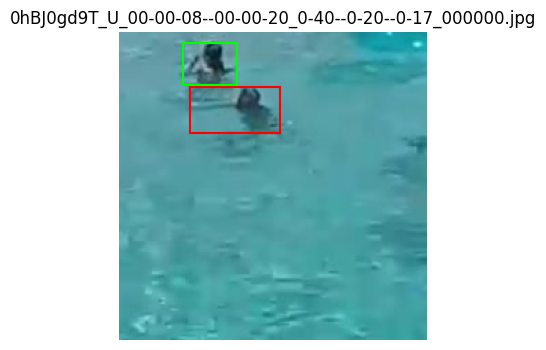

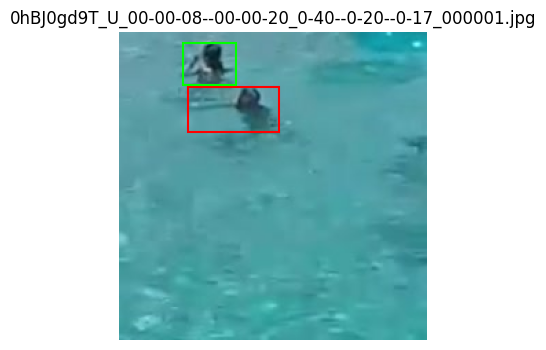

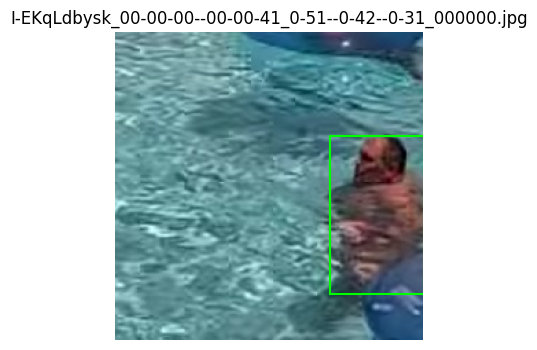

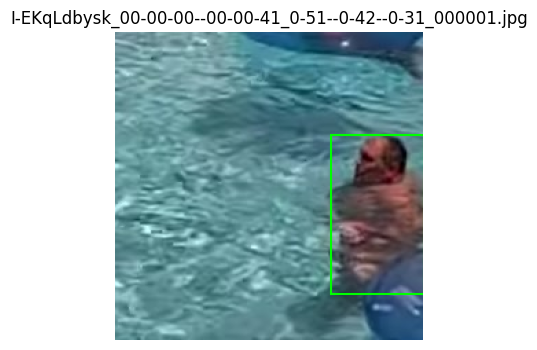

In [5]:
import os, glob, collections
from PIL import Image

OUT = "/content/drive/MyDrive/lifeguard_datasets/Z5cc_v1"
bad_img = bad_lbl = empty = orphans = 0
box_cls = collections.Counter(); per_split = collections.Counter(); per_split_vids = collections.Counter()

for split in ("train", "val", "test"):
    imgs = sorted(glob.glob(f"{OUT}/{split}/images/*.jpg"))
    lbls = {os.path.splitext(os.path.basename(p))[0] for p in glob.glob(f"{OUT}/{split}/labels/*.txt")}
    per_split[split] = len(imgs)
    for p in imgs:
        stem = os.path.splitext(os.path.basename(p))[0]
        try:
            Image.open(p).verify(); 
        except Exception: bad_img += 1
        lp = f"{OUT}/{split}/labels/{stem}.txt"
        if not os.path.exists(lp): orphans += 1; continue
        with open(lp) as f: lines = f.read().splitlines()
        if not lines: empty += 1
        for ln in lines:
            t = ln.split()
            if len(t) != 5 or any(not (0 <= float(v) <= 1) for v in t[1:]): bad_lbl += 1
            else: box_cls[int(t[0])] += 1
    per_split_vids[split] = len({os.path.basename(p).split("_00-")[0] for p in imgs})

print("images per split:", dict(per_split))
print("videos per split:", dict(per_split_vids))
print("boxes per class (0=swim,1=drown):", dict(box_cls))
print("bad images:", bad_img, "| bad labels:", bad_lbl, "| empty labels:", empty, "| orphan images (no label):", orphans)

# quick visual check
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
for split in ("train", "test"):
    labeled = [p for p in glob.glob(f"{OUT}/{split}/images/*.jpg")
               if os.path.getsize(p.replace("images","labels").replace(".jpg",".txt")) > 0]
    for p in labeled[:2]:
        img = Image.open(p); fig, ax = plt.subplots(1, figsize=(4,4)); ax.imshow(img)
        for ln in open(p.replace("images","labels").replace(".jpg",".txt")):
            c, xc, yc, w, h = map(float, ln.split())
            ax.add_patch(Rectangle(((xc-w/2)*224, (yc-h/2)*224), w*224, h*224,
                                   fill=False, edgecolor="red" if c else "lime", lw=1.5))
        ax.set_title(os.path.basename(p)); ax.axis("off"); plt.show()

In [6]:
import os, re, glob, csv, collections
import xml.etree.ElementTree as ET
from PIL import Image

OUT = "/content/drive/MyDrive/lifeguard_datasets/Z5cc_v1"
ZT = "/content/drive/MyDrive/lifeguard_test"

def video_id_of(s):
    m = re.match(r"^(.*?)_\d{2}-\d{2}-\d{2}--\d{2}-\d{2}-\d{2}_", s)
    return m.group(1) if m else None

# 1) manifest columns + per-split counts
man = f"{OUT}/split_manifest.csv"
print("=== split_manifest.csv ===")
if os.path.exists(man):
    rows = list(csv.reader(open(man, newline="")))
    print("header:", rows[0], "| rows:", len(rows)-1)
    vid = collections.defaultdict(set); clip = collections.Counter()
    for r in rows[1:]:
        vid[r[2]].add(r[1]); clip[r[2]] += 1
    for s in ("train","val","test"):
        print(f"  {s}: clips={clip[s]} videos={len(vid[s])}")
    ov = (vid["train"] & vid["val"]) | (vid["train"] & vid["test"]) | (vid["val"] & vid["test"])
    print("  video-level leakage:", ov or "none")
else:
    print("  MISSING manifest")

# 2) recompute from actual files (correct regex)
print("\n=== recompute from images/labels ===")
for split in ("train","val","test"):
    imgs = sorted(glob.glob(f"{OUT}/{split}/images/*.jpg"))
    vids = {video_id_of(os.path.splitext(os.path.basename(p))[0]) for p in imgs}
    clips = {re.sub(r'_\d{6}$','',os.path.splitext(os.path.basename(p))[0]) for p in imgs}
    cls = collections.Counter(); empty = bad = 0; dims = set()
    for p in imgs:
        try: dims.add(Image.open(p).size)
        except Exception: bad += 1
        lp = p.replace("images","labels").replace(".jpg",".txt")
        if not os.path.exists(lp): continue
        lines = open(lp).read().splitlines()
        if not lines: empty += 1
        for ln in lines:
            t = ln.split()
            if len(t)!=5 or not all(0<=float(v)<=1 for v in t[1:]): bad += 1
            else: cls[int(t[0])] += 1
    print(f"  {split}: images={len(imgs)} videos={len(vids)} clips={len(clips)} "
          f"boxes={dict(cls)} empty={empty} bad={bad} dims={dims}")

# 3) empty-label cause
total = withbox = 0
for p in glob.glob(f"{ZT}/annotations/*.xml"):
    for im in ET.parse(p).getroot().iter("image"):
        total += 1
        if list(im.iter("box")): withbox += 1
print(f"\nXML frames={total} with-box={withbox} empty(negative)={total-withbox}")
print(f"extracted images minus XML frames = {len(glob.glob(OUT+'/**/images/*.jpg', recursive=True)) - total}")

=== split_manifest.csv ===
header: ['snippet', 'video_id', 'split', 'frames'] | rows: 91
  train: clips=64 videos=43
  val: clips=14 videos=12
  test: clips=13 videos=7
  video-level leakage: none

=== recompute from images/labels ===
  train: images=33421 videos=43 clips=64 boxes={1: 16818, 0: 51854} empty=205 bad=0 dims={(224, 224)}
  val: images=6830 videos=12 clips=14 boxes={0: 10712, 1: 5350} empty=145 bad=0 dims={(224, 224)}
  test: images=7821 videos=7 clips=13 boxes={0: 12530, 1: 2338} empty=78 bad=0 dims={(224, 224)}

XML frames=48878 with-box=48452 empty(negative)=426
extracted images minus XML frames = -806


In [7]:
import os, re, glob, collections, xml.etree.ElementTree as ET

ZT = "/content/drive/MyDrive/lifeguard_test"
OUT = "/content/drive/MyDrive/lifeguard_datasets/Z5cc_v1"

xmls = sorted(glob.glob(f"{ZT}/annotations/*.xml"))
canonical = [p for p in xmls if re.search(r"_\d{2}-\d{2}-\d{2}--", os.path.basename(p))]
short = [p for p in xmls if p not in canonical]

def counts(paths):
    img = box = empty = 0
    for p in paths:
        for im in ET.parse(p).getroot().iter("image"):
            img += 1
            b = list(im.iter("box")); box += len(b); empty += (1 if not b else 0)
    return img, box, empty

c_img, c_box, c_empty = counts(canonical)
s_img, s_box, _ = counts(short)
print("canonical XMLs:", len(canonical), "-> images", c_img, "boxes", c_box, "empty", c_empty)
for p in short:
    i, b, _ = counts([p])
    print("  short-named:", os.path.basename(p), "-> images", i, "boxes", b)
print("TOTAL XML images (93 files):", c_img + s_img)

# prepared counts
img_total = empty_lbl = 0; box_cls = collections.Counter()
for split in ("train", "val", "test"):
    for p in sorted(glob.glob(f"{OUT}/{split}/images/*.jpg")):
        img_total += 1
        lines = open(p.replace("images","labels").replace(".jpg",".txt")).read().splitlines()
        if not lines: empty_lbl += 1
        for ln in lines: box_cls[int(ln.split()[0])] += 1
print("prepared images:", img_total, "| empty labels:", empty_lbl, "| boxes:", dict(box_cls))
print("extraction extras (images - canonical frames):", img_total - c_img)
print("XML-vs-prepared diff:", (c_img + s_img) - img_total)

# write report to a NEW file (no overwrite)
rep = f"{OUT}/AUDIT_frame_reconciliation.md"
if os.path.exists(rep): rep = f"{OUT}/AUDIT_frame_reconciliation_2.md"
with open(rep, "w") as f:
    f.write(f"# Z5cc frame reconciliation\n\n"
            f"canonical XMLs: {len(canonical)} -> {c_img} images, {c_box} boxes, {c_empty} empty\n"
            f"short-named duplicates: {len(short)} -> {s_img} images\n"
            f"prepared images: {img_total} | empty labels: {empty_lbl} | boxes: {dict(box_cls)}\n"
            f"extraction extras: {img_total - c_img}\n")
print("report written:", rep)

canonical XMLs: 91 -> images 48070 boxes 99602 empty 426
  short-named: XPPOcJNk1S8.xml -> images 449 boxes 990
  short-named: Z9npOp9WhWM.xml -> images 359 boxes 695
TOTAL XML images (93 files): 48878
prepared images: 48072 | empty labels: 428 | boxes: {1: 24506, 0: 75096}
extraction extras (images - canonical frames): 2
XML-vs-prepared diff: 806
report written: /content/drive/MyDrive/lifeguard_datasets/Z5cc_v1/AUDIT_frame_reconciliation.md


In [8]:
import os, re, glob, csv
import xml.etree.ElementTree as ET

ZT = "/content/drive/MyDrive/lifeguard_test"
OUT = "/content/drive/MyDrive/lifeguard_datasets/Z5cc_v1"

def snippet_name(video_id, start, end, x, y, width):
    start = str(start)[:-3].replace(':', '-'); end = str(end)[:-3].replace(':', '-')
    x = str(x)[:-2].replace('.', '-'); y = str(y)[:-2].replace('.', '-'); width = str(width)[:-2].replace('.', '-')
    return f"{video_id}_{start}--{end}_{x}--{y}--{width}"

# 1) labeled clips from datalist (only those with a canonical XML)
clips = []
with open(f"{ZT}/datalist.csv", newline="") as f:
    for row in csv.reader(f):
        if len(row) < 7: continue
        video_id, start, end, x, y, width, flag = row[:7]
        if flag.strip() != "y": continue
        snip = snippet_name(video_id, start, end, x, y, width)
        if os.path.exists(f"{ZT}/annotations/{snip}.xml"):
            clips.append((snip, video_id))

print("labeled clips with XML:", len(clips))

rows = []; tot_missing = tot_extra = tot_dup = 0; missing_clips = []
for snip, vid in clips:
    xml_ids = [int(im.get("id")) for im in ET.parse(f"{ZT}/annotations/{snip}.xml").getroot().iter("image")]
    xml_set = set(xml_ids); n_xml = len(xml_set); dup_xml = len(xml_ids) - n_xml

    imgs = sorted(glob.glob(f"{OUT}/**/images/{snip}_*.jpg", recursive=True))
    img_ids = [int(re.search(r'_(\d{6})\.jpg$', os.path.basename(p)).group(1)) for p in imgs]
    img_set = set(img_ids); n_img = len(img_set); dup_img = len(img_ids) - n_img

    missing = sorted(xml_set - img_set)   # annotated frame with no exported image
    extra   = sorted(img_set - xml_set)   # exported image with no annotation
    tot_missing += len(missing); tot_extra += len(extra); tot_dup += dup_xml + dup_img
    status = "OK" if not (missing or extra or dup_xml or dup_img) else "MISMATCH"
    if missing: missing_clips.append((vid, snip, n_xml, n_img, missing))
    rows.append((snip, vid, n_xml, n_img, n_img - n_xml, len(missing), len(extra), dup_xml, dup_img, status))

print(f"\nclips={len(clips)} | total MISSING frames={tot_missing} | total EXTRA frames={tot_extra} | total duplicate ids={tot_dup}")
print("clips with missing annotated frames:", len(missing_clips))
for vid, snip, nx, ni, miss in missing_clips:
    print(f"  MISSING  {vid}  XML={nx} exported={ni}  missing_ids={miss}")

# 2) short-named XML exclusion check
short = [p for p in glob.glob(f"{ZT}/annotations/*.xml")
         if not re.search(r"_\d{2}-\d{2}-\d{2}--", os.path.basename(p))]
print("\nshort-named XMLs (should be 2, NOT referenced by datalist):")
for s in short:
    base = os.path.splitext(os.path.basename(s))[0]
    referenced = any(c[0].startswith(base + "_") for c in clips)
    print(f"  {os.path.basename(s)} -> referenced_by_datalist={referenced}")

# 3) write report to a NEW file
rep = f"{OUT}/AUDIT_per_clip_frame_reconciliation.md"
if os.path.exists(rep): rep = f"{OUT}/AUDIT_per_clip_frame_reconciliation_2.md"
with open(rep, "w") as f:
    f.write("# Per-clip frame reconciliation (Z5cc)\n\n")
    f.write("| snippet | video | XML frames | exported | diff | missing | extra | dup_xml | dup_img | status |\n")
    f.write("|---|---|---|---|---|---|---|---|---|---|\n")
    for snip, vid, nx, ni, diff, nmiss, nextra, dx, di, status in rows:
        f.write(f"| {snip} | {vid} | {nx} | {ni} | {diff:+d} | {nmiss} | {nextra} | {dx} | {di} | {status} |\n")
    f.write(f"\n## Summary\n\nclips={len(clips)} | missing={tot_missing} | extra={tot_extra} | dup={tot_dup}\n")
    f.write(f"clips with missing annotated frames: {len(missing_clips)}\n")
print("report written:", rep)

labeled clips with XML: 91

clips=91 | total MISSING frames=0 | total EXTRA frames=2 | total duplicate ids=0
clips with missing annotated frames: 0

short-named XMLs (should be 2, NOT referenced by datalist):
  XPPOcJNk1S8.xml -> referenced_by_datalist=True
  Z9npOp9WhWM.xml -> referenced_by_datalist=True
report written: /content/drive/MyDrive/lifeguard_datasets/Z5cc_v1/AUDIT_per_clip_frame_reconciliation.md


In [9]:
import os, re, glob, csv
import xml.etree.ElementTree as ET

ZT = "/content/drive/MyDrive/lifeguard_test"
OUT = "/content/drive/MyDrive/lifeguard_datasets/Z5cc_v1"

def snippet_name(video_id, start, end, x, y, width):
    start = str(start)[:-3].replace(':', '-'); end = str(end)[:-3].replace(':', '-')
    x = str(x)[:-2].replace('.', '-'); y = str(y)[:-2].replace('.', '-'); width = str(width)[:-2].replace('.', '-')
    return f"{video_id}_{start}--{end}_{x}--{y}--{width}"

rows = []
with open(f"{ZT}/datalist.csv", newline="") as f:
    for row in csv.reader(f):
        if len(row) < 7: continue
        video_id, start, end, x, y, width, flag = row[:7]
        if flag.strip() != "y": continue
        rows.append((video_id, start, end, snippet_name(video_id, start, end, x, y, width)))

snippets = {r[3] for r in rows}
video_ids = {r[0] for r in rows}

def annotation_data(p):
    r = ET.parse(p).getroot()
    return {int(im.get("id")): [(b.get("label"), round(float(b.get("xtl")),2), round(float(b.get("ytl")),2),
                                 round(float(b.get("xbr")),2), round(float(b.get("ybr")),2))
            for b in im.iter("box")] for im in r.iter("image")}

short = [p for p in glob.glob(f"{ZT}/annotations/*.xml")
         if not re.search(r"_\d{2}-\d{2}-\d{2}--", os.path.basename(p))]

report_lines = ["# Short-named XML audit\n"]
for s in sorted(short):
    base = os.path.splitext(os.path.basename(s))[0]
    exact = base in snippets                       # exact clip/snippet match
    vidmatch = base in video_ids                   # is it a video id?
    prefix = any(sn.startswith(base + "_") for sn in snippets)  # the buggy check
    print(f"\n=== {base}.xml ===")
    print(f"  exact snippet match: {exact} | video-id match: {vidmatch} | prefix match (buggy): {prefix}")

    print("  datalist rows for this video:")
    for r in rows:
        if r[0] == base:
            print(f"    video_id={r[0]} start={r[1]} end={r[2]}\n      snippet={r[3]}")

    canon = sorted(glob.glob(f"{ZT}/annotations/{base}_*.xml"))
    s_data = annotation_data(s)
    print(f"  short-named: {len(s_data)} images, {sum(len(v) for v in s_data.values())} boxes")
    for c in canon:
        c_data = annotation_data(c)
        same = s_data == c_data
        print(f"    vs {os.path.basename(c)}: {len(c_data)} images, "
              f"{sum(len(v) for v in c_data.values())} boxes, identical_annotations={same}")
        report_lines.append(f"- {base}.xml vs {os.path.basename(c)}: identical={same} "
                            f"({len(c_data)} images)\n")

    imgs = glob.glob(f"{OUT}/**/images/{base}_*.jpg", recursive=True)
    print(f"  prepared dataset images for this video: {len(imgs)}")

rep = f"{OUT}/AUDIT_short_xml_status.md"
if os.path.exists(rep): rep = f"{OUT}/AUDIT_short_xml_status_2.md"
with open(rep, "w") as f:
    f.write("\n".join(report_lines))
print("\nreport written:", rep)


=== XPPOcJNk1S8.xml ===
  exact snippet match: False | video-id match: True | prefix match (buggy): True
  datalist rows for this video:
    video_id=XPPOcJNk1S8 start=00:00:05.32 end=00:00:20.30
      snippet=XPPOcJNk1S8_00-00-05--00-00-20_0-70--0-27--0-11
  short-named: 449 images, 990 boxes
    vs XPPOcJNk1S8_00-00-05--00-00-20_0-70--0-27--0-11.xml: 449 images, 990 boxes, identical_annotations=True
  prepared dataset images for this video: 449

=== Z9npOp9WhWM.xml ===
  exact snippet match: False | video-id match: True | prefix match (buggy): True
  datalist rows for this video:
    video_id=Z9npOp9WhWM start=00:00:00.00 end=00:00:13.92
      snippet=Z9npOp9WhWM_00-00-00--00-00-13_0-56--0-32--0-66
    video_id=Z9npOp9WhWM start=00:00:04.09 end=00:00:15.23
      snippet=Z9npOp9WhWM_00-00-04--00-00-15_0-46--0-32--0-66
    video_id=Z9npOp9WhWM start=00:00:22.73 end=00:00:34.68
      snippet=Z9npOp9WhWM_00-00-22--00-00-34_0-04--0-25--0-17
  short-named: 359 images, 695 boxes
    vs Z9n